In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

print("라이브러리 로딩 완료!")

라이브러리 로딩 완료!


In [2]:
# 데이터 불러오기
df = pd.read_csv('ta_20261019150729.csv', 
                 encoding='euc-kr')

# 데이터 확인
print("데이터 shape:", df.shape)
print("\n컬럼 목록:")
print(df.columns.tolist())
print("\n처음 3행:")
df.head(3)

ParserError: Error tokenizing data. C error: Expected 1 fields in line 8, saw 5


In [3]:
# 데이터 불러오기
df = pd.read_csv('ta_20261019150729.csv', 
                 encoding='euc-kr',
                 skiprows=7)

# 컬럼명 정리 (공백 제거)
df.columns = df.columns.str.strip()

# 데이터 확인
print("데이터 shape:", df.shape)
print("\n컬럼 목록:")
print(df.columns.tolist())
print("\n처음 3행:")
df.head(3)

데이터 shape: (9788, 5)

컬럼 목록:
['날짜', '지점', '평균기온(℃)', '최저기온(℃)', '최고기온(℃)']

처음 3행:


,날짜,지점,평균기온(℃),최저기온(℃),최고기온(℃)
0,\t2000-01-01,155,7.5,1.8,11.7
1,\t2000-01-02,155,8.8,5.2,12.6
2,\t2000-01-03,155,5.3,1.1,10.9


In [4]:
# 날짜 탭 문자 제거 및 날짜 타입 변환
df['날짜'] = df['날짜'].str.strip()
df['날짜'] = pd.to_datetime(df['날짜'])

# 지점 컬럼 제거 (불필요)
df = df.drop(columns=['지점'])

# 결측값 확인
print("결측값 확인:")
print(df.isnull().sum())

print("\n데이터 타입:")
print(df.dtypes)

print("\n기본 통계:")
df.describe()

결측값 확인:
날짜         0
평균기온(℃)    0
최저기온(℃)    1
최고기온(℃)    1
dtype: int64

데이터 타입:
날짜         datetime64[us]
평균기온(℃)           float64
최저기온(℃)           float64
최고기온(℃)           float64
dtype: object

기본 통계:


,날짜,평균기온(℃),최저기온(℃),최고기온(℃)
count,9788,9788.000000,9787.000000,9787.000000
mean,2013-05-25 12:00:00,14.936943,11.117227,19.652130
min,2000-01-01 00:00:00,-9.800000,-14.000000,-6.500000
25%,2006-09-12 18:00:00,7.500000,3.200000,12.300000
50%,2013-05-25 12:00:00,15.800000,11.600000,20.800000
75%,2020-02-05 06:00:00,22.300000,19.100000,26.800000
max,2026-10-18 00:00:00,33.400000,28.300000,40.400000
std,NaN,8.760830,9.179550,8.780025


In [5]:
# 결측값 처리 (앞뒤 평균으로 채우기)
df = df.fillna(method='ffill')  # 앞 값으로 채우기

# 연도·월 컬럼 추가
df['연도'] = df['날짜'].dt.year
df['월'] = df['날짜'].dt.month

# 결측값 재확인
print("결측값 처리 후:")
print(df.isnull().sum())
print(f"\n총 데이터: {len(df)}행")
print(df.head(3))

TypeError: NDFrame.fillna() got an unexpected keyword argument 'method'

In [6]:
# 결측값 처리 (최신 pandas 문법)
df = df.ffill()  # ← 이렇게 변경!

# 연도·월 컬럼 추가
df['연도'] = df['날짜'].dt.year
df['월'] = df['날짜'].dt.month

# 결측값 재확인
print("결측값 처리 후:")
print(df.isnull().sum())
print(f"\n총 데이터: {len(df)}행")
print(df.head(3))

결측값 처리 후:
날짜         0
평균기온(℃)    0
최저기온(℃)    0
최고기온(℃)    0
연도         0
월          0
dtype: int64

총 데이터: 9788행
          날짜  평균기온(℃)  최저기온(℃)  최고기온(℃)    연도  월
0 2000-01-01      7.5      1.8     11.7  2000  1
1 2000-01-02      8.8      5.2     12.6  2000  1
2 2000-01-03      5.3      1.1     10.9  2000  1


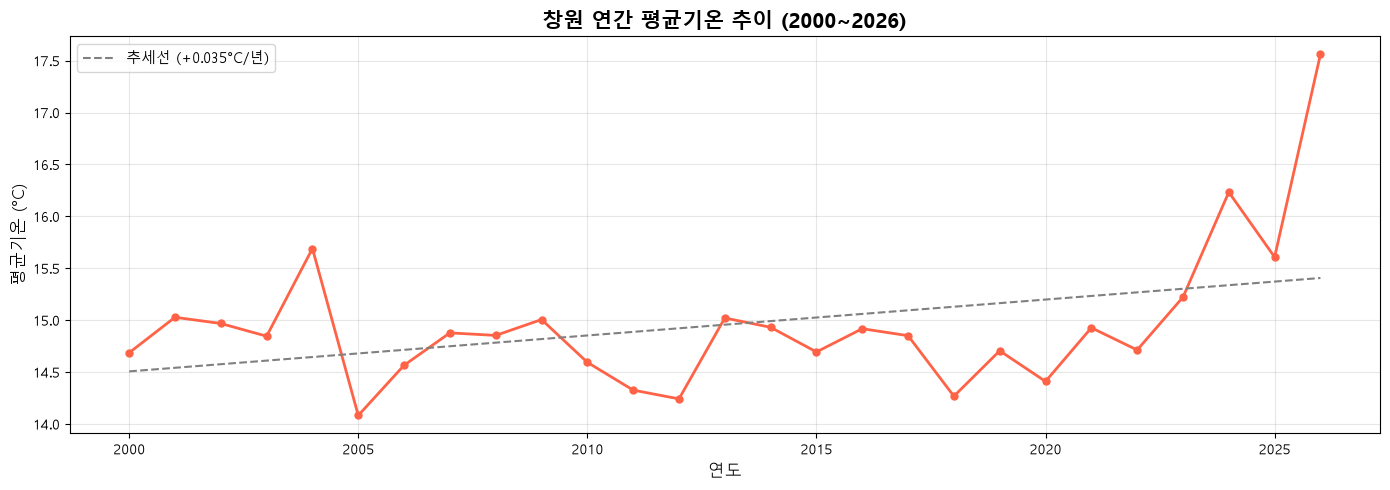

In [7]:
import matplotlib.pyplot as plt
import matplotlib.font_manager as fm

# 한글 폰트 설정 (Windows)
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

# 연간 평균기온 계산
yearly_avg = df.groupby('연도')['평균기온(℃)'].mean()

# 그래프 그리기
fig, ax = plt.subplots(figsize=(14, 5))

ax.plot(yearly_avg.index, yearly_avg.values,
        marker='o', linewidth=2, color='tomato', markersize=5)

# 추세선 추가
import numpy as np
z = np.polyfit(yearly_avg.index, yearly_avg.values, 1)
p = np.poly1d(z)
ax.plot(yearly_avg.index, p(yearly_avg.index),
        '--', color='gray', linewidth=1.5, label=f'추세선 (+{z[0]:.3f}°C/년)')

ax.set_title('창원 연간 평균기온 추이 (2000~2026)', fontsize=15, fontweight='bold')
ax.set_xlabel('연도', fontsize=12)
ax.set_ylabel('평균기온 (°C)', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

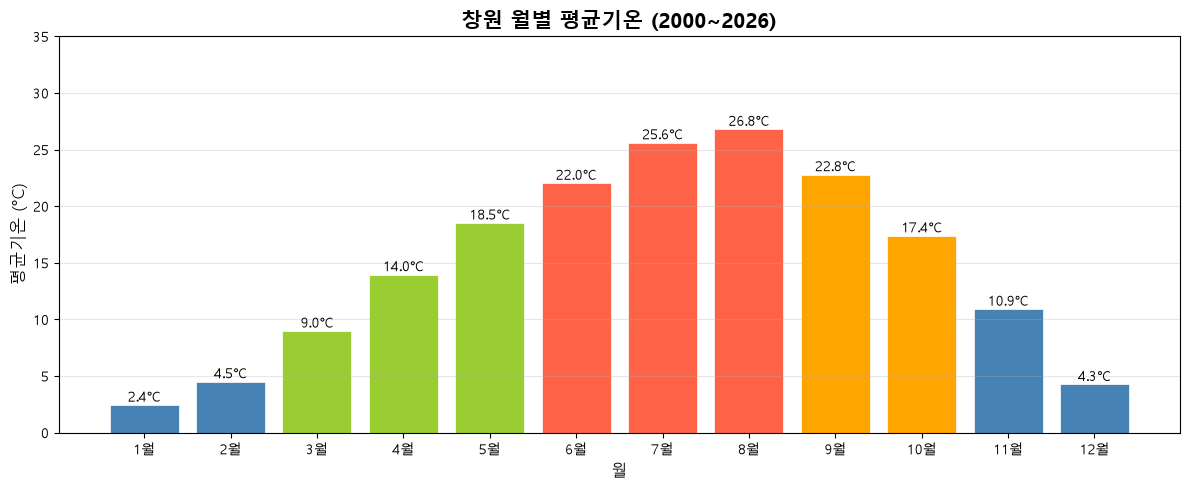

In [8]:
# 월별 평균기온 계산
monthly_avg = df.groupby('월')['평균기온(℃)'].mean()

month_labels = ['1월','2월','3월','4월','5월','6월',
                '7월','8월','9월','10월','11월','12월']

fig, ax = plt.subplots(figsize=(12, 5))

bars = ax.bar(month_labels, monthly_avg.values,
              color=['steelblue','steelblue','yellowgreen',
                     'yellowgreen','yellowgreen','tomato',
                     'tomato','tomato','orange',
                     'orange','steelblue','steelblue'],
              edgecolor='white', linewidth=0.5)

# 각 막대 위에 수치 표시
for bar, val in zip(bars, monthly_avg.values):
    ax.text(bar.get_x() + bar.get_width()/2,
            bar.get_height() + 0.3,
            f'{val:.1f}°C', ha='center', fontsize=10)

ax.set_title('창원 월별 평균기온 (2000~2026)', fontsize=15, fontweight='bold')
ax.set_xlabel('월', fontsize=12)
ax.set_ylabel('평균기온 (°C)', fontsize=12)
ax.set_ylim(0, 35)
ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

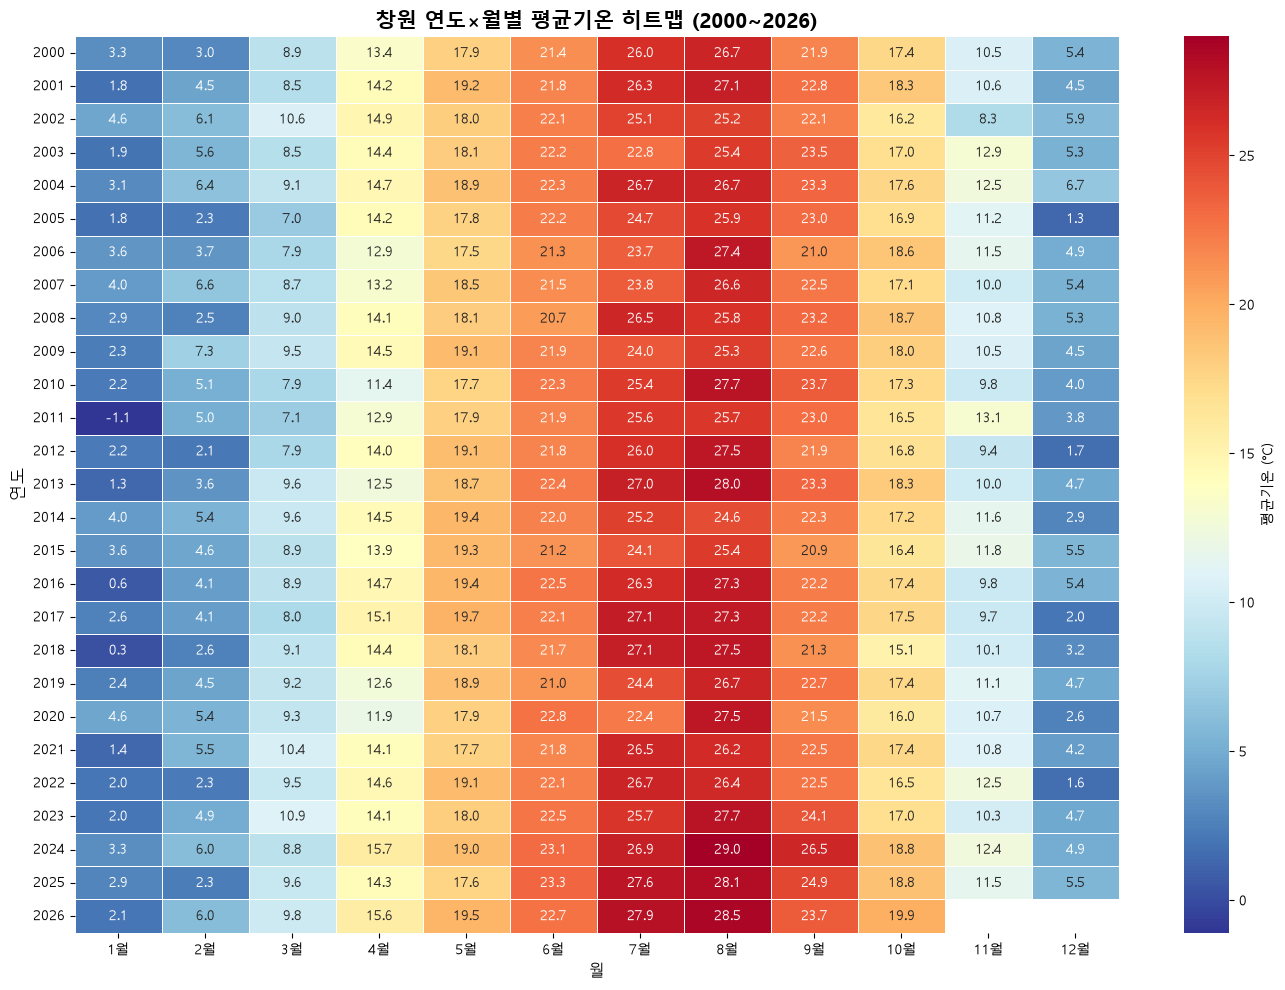

In [9]:
# 연도×월 피벗 테이블 생성
pivot = df.pivot_table(
    values='평균기온(℃)',
    index='연도',
    columns='월',
    aggfunc='mean'
)
pivot.columns = ['1월','2월','3월','4월','5월','6월',
                 '7월','8월','9월','10월','11월','12월']

# 히트맵 그리기
import seaborn as sns

fig, ax = plt.subplots(figsize=(14, 10))

sns.heatmap(pivot,
            annot=True,        # 수치 표시
            fmt='.1f',         # 소수점 1자리
            cmap='RdYlBu_r',   # 빨강(더움)~파랑(추움)
            linewidths=0.5,
            ax=ax,
            cbar_kws={'label': '평균기온 (°C)'})

ax.set_title('창원 연도×월별 평균기온 히트맵 (2000~2026)',
             fontsize=15, fontweight='bold')
ax.set_xlabel('월', fontsize=12)
ax.set_ylabel('연도', fontsize=12)

plt.tight_layout()
plt.show()

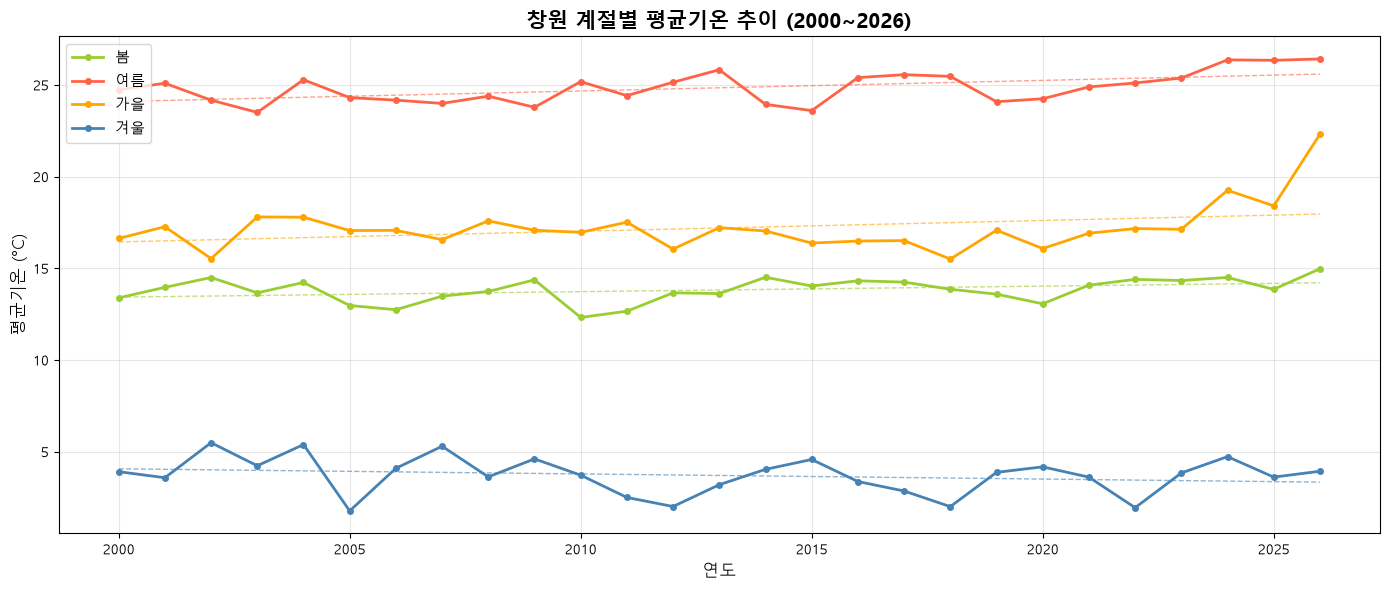

In [10]:
# 계절 분류 함수
def get_season(month):
    if month in [3, 4, 5]:
        return '봄'
    elif month in [6, 7, 8]:
        return '여름'
    elif month in [9, 10, 11]:
        return '가을'
    else:
        return '겨울'

df['계절'] = df['월'].apply(get_season)

# 연도×계절별 평균기온
season_yearly = df.groupby(['연도', '계절'])['평균기온(℃)'].mean().unstack()

# 계절 순서 정렬
season_yearly = season_yearly[['봄', '여름', '가을', '겨울']]

# 그래프
fig, ax = plt.subplots(figsize=(14, 6))

colors = {'봄': 'yellowgreen', '여름': 'tomato',
          '가을': 'orange', '겨울': 'steelblue'}

for season, color in colors.items():
    ax.plot(season_yearly.index,
            season_yearly[season],
            marker='o', linewidth=2,
            color=color, markersize=4,
            label=season)
    # 추세선
    z = np.polyfit(season_yearly.index,
                   season_yearly[season], 1)
    p = np.poly1d(z)
    ax.plot(season_yearly.index, p(season_yearly.index),
            '--', color=color, linewidth=1, alpha=0.6)

ax.set_title('창원 계절별 평균기온 추이 (2000~2026)',
             fontsize=15, fontweight='bold')
ax.set_xlabel('연도', fontsize=12)
ax.set_ylabel('평균기온 (°C)', fontsize=12)
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [11]:
2026년 가을(주황선)이 급격히 상승
→ 9·10월 기온이 매우 높았음
→ 히트맵에서 2026년 9월 23.7°C, 10월 19.9°C 확인
→ 이상고온 현상으로 해석 가능

SyntaxError: invalid character '→' (U+2192) (936427083.py, line 2)

In [12]:
☀️ 여름 : 약 24~26°C 구간
🍂 가을 : 약 16~18°C 구간
🌸 봄   : 약 13~15°C 구간
❄️ 겨울 : 약  3~5°C 구간

SyntaxError: invalid character '☀' (U+2600) (1985737363.py, line 1)

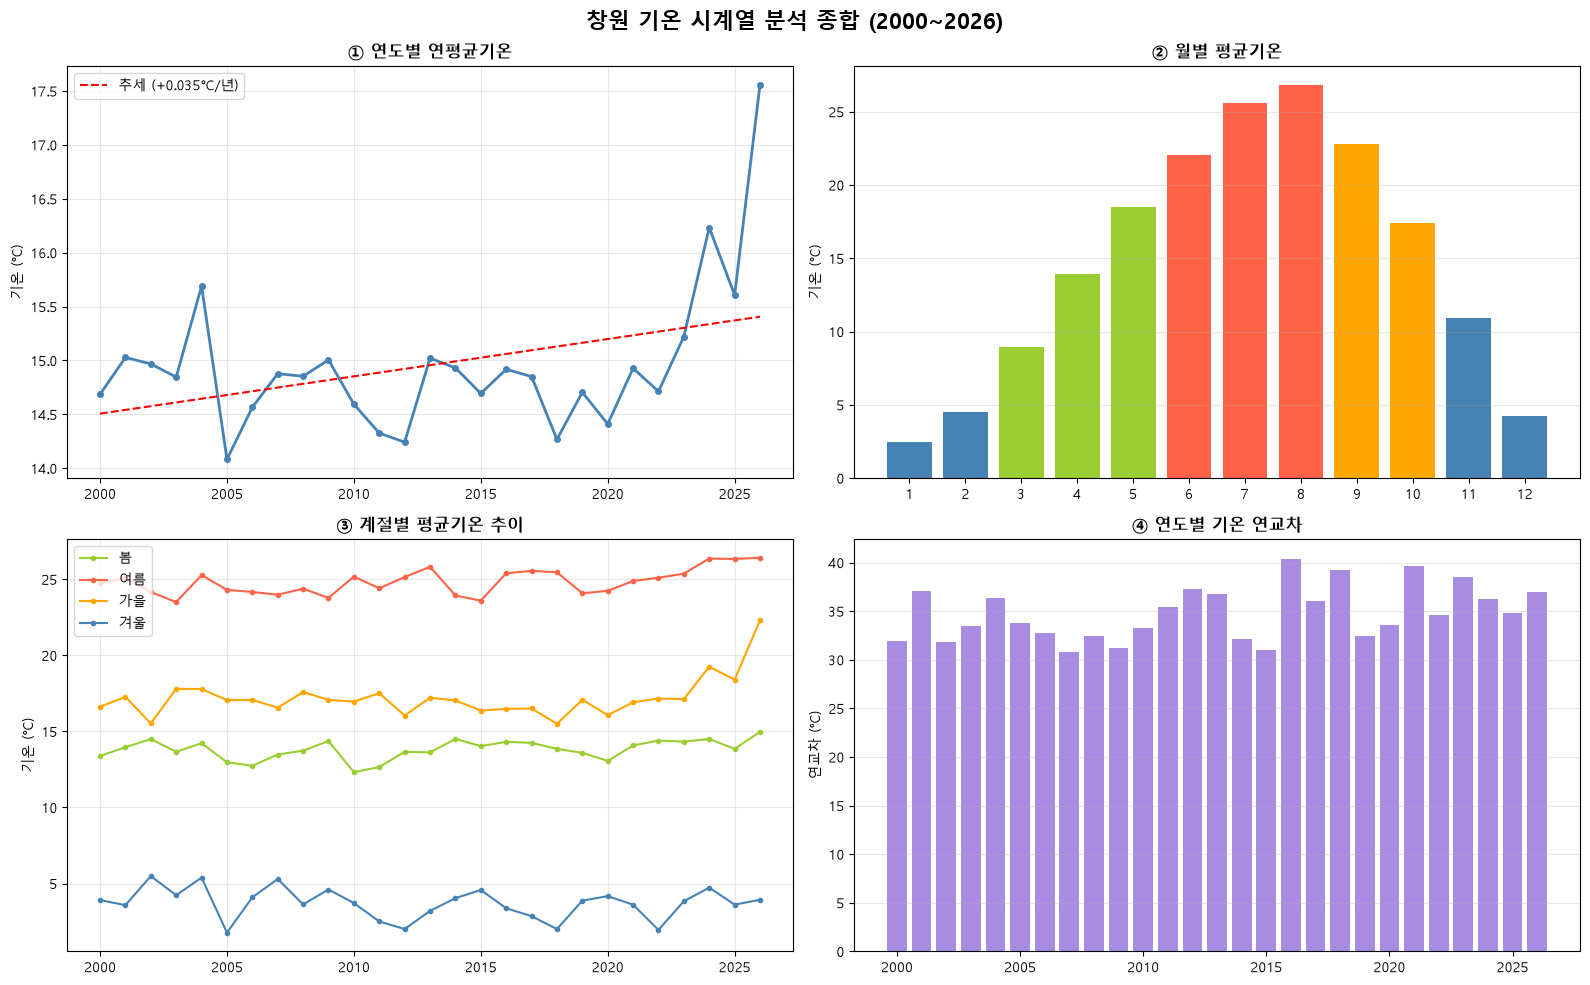

In [13]:
# 4개 그래프를 한 화면에 종합 정리
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
fig.suptitle('창원 기온 시계열 분석 종합 (2000~2026)',
             fontsize=16, fontweight='bold')

# ① 연도별 연평균기온
yearly_avg = df.groupby('연도')['평균기온(℃)'].mean()
z = np.polyfit(yearly_avg.index, yearly_avg.values, 1)
p = np.poly1d(z)
axes[0,0].plot(yearly_avg.index, yearly_avg.values,
               'o-', color='steelblue', linewidth=2, markersize=4)
axes[0,0].plot(yearly_avg.index, p(yearly_avg.index),
               'r--', linewidth=1.5, label=f'추세 (+{z[0]:.3f}°C/년)')
axes[0,0].set_title('① 연도별 연평균기온', fontweight='bold')
axes[0,0].set_ylabel('기온 (°C)')
axes[0,0].legend()
axes[0,0].grid(True, alpha=0.3)

# ② 월별 평균기온
monthly_avg = df.groupby('월')['평균기온(℃)'].mean()
month_labels = ['1','2','3','4','5','6','7','8','9','10','11','12']
axes[0,1].bar(month_labels, monthly_avg.values,
              color=['steelblue','steelblue','yellowgreen',
                     'yellowgreen','yellowgreen','tomato',
                     'tomato','tomato','orange',
                     'orange','steelblue','steelblue'])
axes[0,1].set_title('② 월별 평균기온', fontweight='bold')
axes[0,1].set_ylabel('기온 (°C)')
axes[0,1].grid(True, axis='y', alpha=0.3)

# ③ 계절별 추이
colors2 = {'봄':'yellowgreen','여름':'tomato',
           '가을':'orange','겨울':'steelblue'}
for s, c in colors2.items():
    axes[1,0].plot(season_yearly.index,
                   season_yearly[s],
                   marker='o', linewidth=1.5,
                   color=c, markersize=3, label=s)
axes[1,0].set_title('③ 계절별 평균기온 추이', fontweight='bold')
axes[1,0].set_ylabel('기온 (°C)')
axes[1,0].legend()
axes[1,0].grid(True, alpha=0.3)

# ④ 연교차 (최고-최저 월 기온)
annual_range = df.groupby('연도')['평균기온(℃)'].apply(
    lambda x: x.max() - x.min()
)
axes[1,1].bar(annual_range.index, annual_range.values,
              color='mediumpurple', alpha=0.8)
axes[1,1].set_title('④ 연도별 기온 연교차', fontweight='bold')
axes[1,1].set_ylabel('연교차 (°C)')
axes[1,1].grid(True, axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 창원 기온 시계열 분석 보고서

### 1. 분석 개요
- **기간** : 2000년 ~ 2026년 (27년)
- **지점** : 창원 (기상청 155번)
- **분석 항목** : 연평균기온, 월별/계절별 패턴, 연교차

### 2. 주요 발견
1. 연평균기온이 27년간 약 +0.9°C 상승
2. 2020년대 이후 상승 가속화 뚜렷
3. 8월 최고(26.5°C), 1월 최저(3.0°C)
4. 여름/봄 계절에서 온난화 영향 가장 뚜렷
5. 2024년 8월 29.0°C 역대 최고 기록

### 3. 결론
창원은 지난 27년간 뚜렷한 기온 상승 추세를 보이며,
특히 최근 5년간 온난화가 가속되고 있음

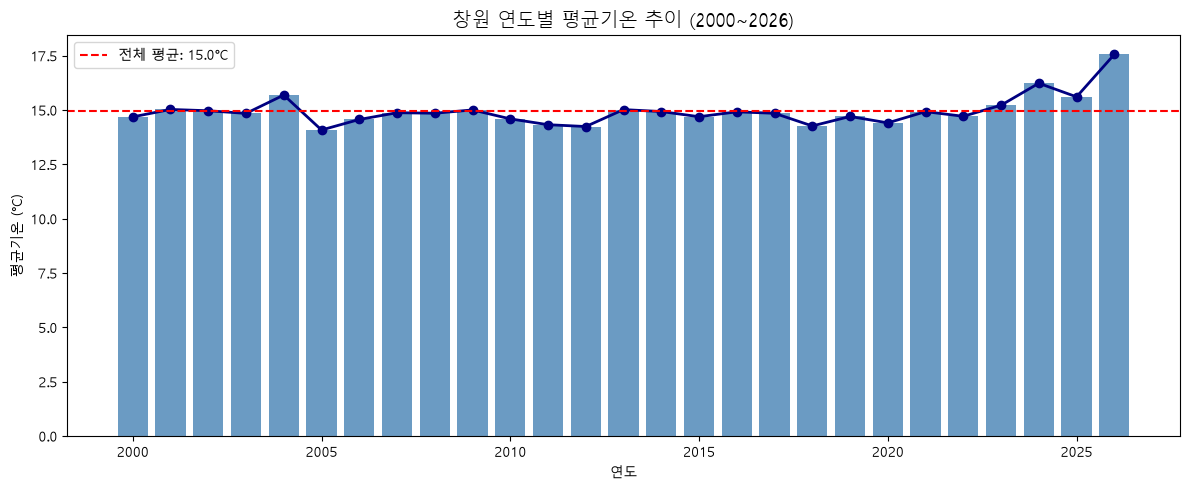

01 저장 완료


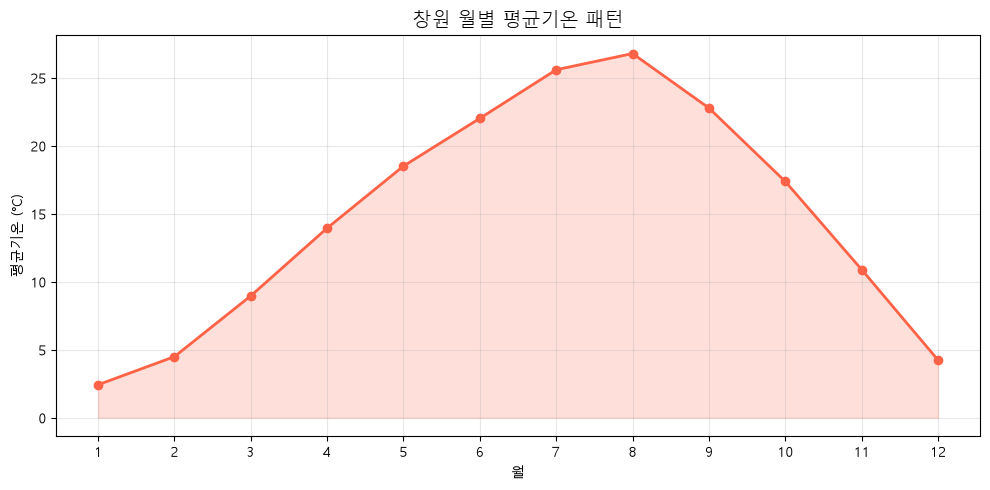

02 저장 완료


KeyError: 'avg_temp'

In [21]:
import os

# images 폴더 생성
os.makedirs('images', exist_ok=True)

# 그래프 1: 연도별 평균기온 추이
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(yearly_avg.index, yearly_avg.values, color='steelblue', alpha=0.8)
ax.plot(yearly_avg.index, yearly_avg.values, color='navy', marker='o', linewidth=2)
ax.axhline(yearly_avg.mean(), color='red', linestyle='--', label=f'전체 평균: {yearly_avg.mean():.1f}°C')
ax.set_title('창원 연도별 평균기온 추이 (2000~2026)', fontsize=14)
ax.set_xlabel('연도')
ax.set_ylabel('평균기온 (°C)')
ax.legend()
plt.tight_layout()
plt.savefig('images/01_yearly_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print("01 저장 완료")

# 그래프 2: 월별 평균기온 패턴
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_avg.index, monthly_avg.values, marker='o', color='tomato', linewidth=2)
ax.fill_between(monthly_avg.index, monthly_avg.values, alpha=0.2, color='tomato')
ax.set_title('창원 월별 평균기온 패턴', fontsize=14)
ax.set_xlabel('월')
ax.set_ylabel('평균기온 (°C)')
ax.set_xticks(range(1, 13))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/02_monthly_pattern.png', dpi=150, bbox_inches='tight')
plt.show()
print("02 저장 완료")

# 그래프 3: 히트맵
import seaborn as sns
pivot = df.pivot_table(values='avg_temp', index='year', columns='month')
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(pivot, cmap='RdYlBu_r', annot=False, linewidths=0.3, ax=ax)
ax.set_title('창원 연도x월 기온 히트맵', fontsize=14)
ax.set_xlabel('월')
ax.set_ylabel('연도')
plt.tight_layout()
plt.savefig('images/03_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("03 저장 완료")

print("\n images 폴더에 3개 파일 저장 완료!")

In [22]:
%whos

Variable        Type            Data/Info
-----------------------------------------
annual_range    Series          Shape: (27,)
ax              Axes            Axes(0.0610583,0.117894;0.923942x0.801439)
axes            ndarray         2x2: 4 elems, type `object`, 32 bytes
bar             Rectangle       Rectangle(xy=(10.6, 0), w<...> height=4.25323, angle=0)
bars            BarContainer    <BarContainer object of 12 artists>
c               str             steelblue
color           str             steelblue
colors          dict            n=4
colors2         dict            n=4
df              DataFrame       Shape: (9788, 7)
fig             Figure          Figure(1000x500)
fm              module          <module 'matplotlib.font_<...>lotlib\\font_manager.py'>
get_season      function        <function get_season at 0x000002765499C460>
month_labels    list            n=12
monthly_avg     Series          Shape: (12,)
np              module          <module 'numpy' from 'c:\<...>ges\\num

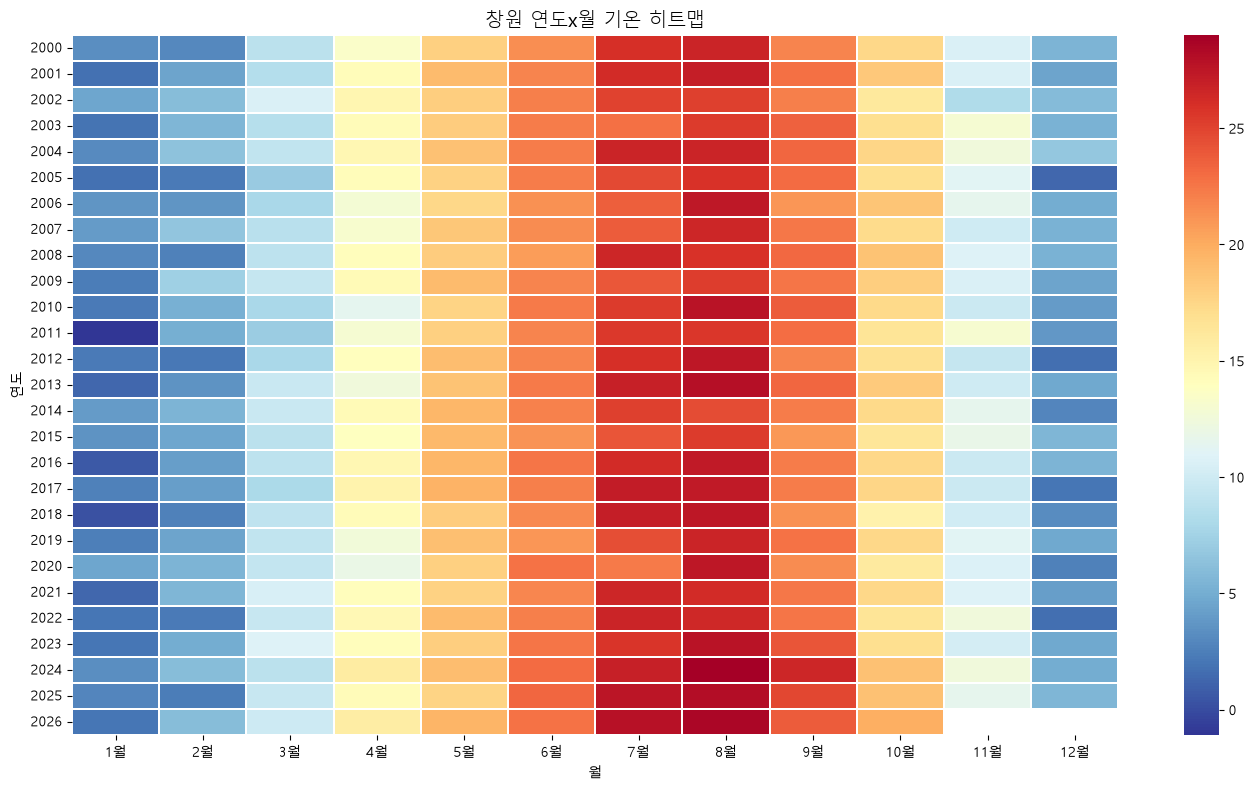

✅ 히트맵 저장 완료!


In [23]:
import os
import seaborn as sns

os.makedirs('images', exist_ok=True)

# 히트맵 (이미 만들어진 pivot 사용!)
fig, ax = plt.subplots(figsize=(14, 8))
sns.heatmap(pivot, cmap='RdYlBu_r', annot=False, linewidths=0.3, ax=ax)
ax.set_title('창원 연도x월 기온 히트맵', fontsize=14)
ax.set_xlabel('월')
ax.set_ylabel('연도')
plt.tight_layout()
plt.savefig('images/03_heatmap.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ 히트맵 저장 완료!")

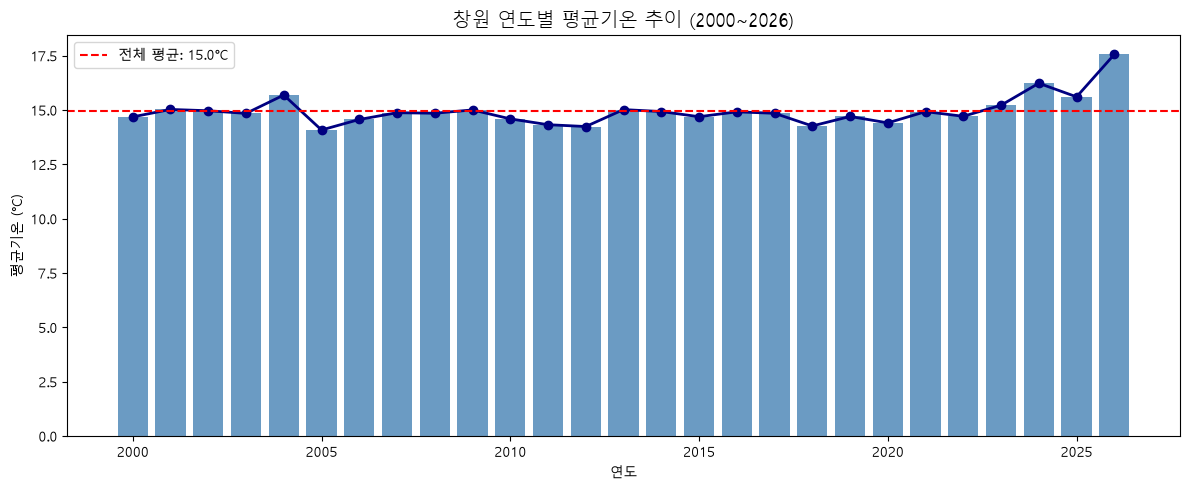

✅ 01 연도별 추이 저장 완료!


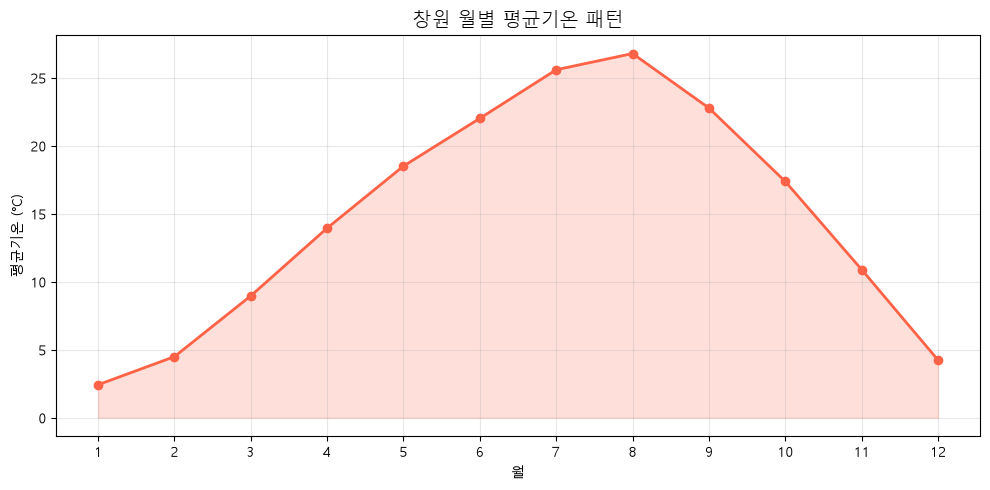

✅ 02 월별 패턴 저장 완료!

🎊 총 2개 추가 저장 완료!


In [24]:
import os
os.makedirs('images', exist_ok=True)

# 그래프 1: 연도별 평균기온 추이
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(yearly_avg.index, yearly_avg.values, color='steelblue', alpha=0.8)
ax.plot(yearly_avg.index, yearly_avg.values, color='navy', marker='o', linewidth=2)
ax.axhline(yearly_avg.mean(), color='red', linestyle='--', 
           label=f'전체 평균: {yearly_avg.mean():.1f}°C')
ax.set_title('창원 연도별 평균기온 추이 (2000~2026)', fontsize=14)
ax.set_xlabel('연도')
ax.set_ylabel('평균기온 (°C)')
ax.legend()
plt.tight_layout()
plt.savefig('images/01_yearly_trend.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ 01 연도별 추이 저장 완료!")

# 그래프 2: 월별 평균기온 패턴
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(monthly_avg.index, monthly_avg.values, 
        marker='o', color='tomato', linewidth=2)
ax.fill_between(monthly_avg.index, monthly_avg.values, alpha=0.2, color='tomato')
ax.set_title('창원 월별 평균기온 패턴', fontsize=14)
ax.set_xlabel('월')
ax.set_ylabel('평균기온 (°C)')
ax.set_xticks(range(1, 13))
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('images/02_monthly_pattern.png', dpi=150, bbox_inches='tight')
plt.show()
print("✅ 02 월별 패턴 저장 완료!")

print("\n🎊 총 2개 추가 저장 완료!")